# 7. Modelo final, evaluación en test y predictor


Primer y único uso del conjunto de test.

In [1]:
import warnings
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

import sys
from pathlib import Path

PROJECT_PATH = Path("..").resolve()
DATA_PATH = PROJECT_PATH / "data"
FIGURES_PATH = PROJECT_PATH / "figures"
sys.path.append(str(PROJECT_PATH))
RANDOM_STATE = 42

warnings.filterwarnings("ignore")
from predictor import TARGET, CATEGORICAL_FEATURES, MODEL_PATH, engineer_features, encode_categories, predictor

## 7.1 Carga de train, test, hiperparámetros y umbral

In [2]:
train_reservations = pd.read_csv(DATA_PATH / "train.csv")
test_reservations = pd.read_csv(DATA_PATH / "test.csv")
with open(DATA_PATH / "lightgbm_hyperparameters.json") as file:
    lightgbm_hyperparameters = json.load(file)
with open(DATA_PATH / "decision_threshold.json") as file:
    decision_threshold = json.load(file)["decision_threshold"]

X_train = engineer_features(train_reservations)
train_categories = {column: sorted(X_train[column].unique()) for column in CATEGORICAL_FEATURES}
X_train_category = encode_categories(X_train, train_categories)
X_test_category = encode_categories(engineer_features(test_reservations), train_categories)
y_train, y_test = train_reservations[TARGET], test_reservations[TARGET]
print(X_train_category.shape, X_test_category.shape, f"umbral = {decision_threshold}")

(38273, 45) (9569, 45) umbral = 0.41


## 7.2 Entrenamiento con todo train y evaluación en test

In [3]:
final_model = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, **lightgbm_hyperparameters)
final_model.fit(X_train_category, y_train)

test_probabilities = final_model.predict_proba(X_test_category)[:, 1]
test_predictions = (test_probabilities >= decision_threshold).astype(int)
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, test_predictions):.4f}")
print(f"Test ROC-AUC:           {roc_auc_score(y_test, test_probabilities):.4f}")
print(f"Test BA con umbral 0.5: {balanced_accuracy_score(y_test, test_probabilities >= 0.5):.4f}")

Test balanced accuracy: 0.8923
Test ROC-AUC:           0.9634
Test BA con umbral 0.5: 0.8890


In [4]:
print(classification_report(y_test, test_predictions, target_names=["no cancela", "cancela"], digits=3))

              precision    recall  f1-score   support

  no cancela      0.912     0.907     0.909      5578
     cancela      0.871     0.878     0.874      3991

    accuracy                          0.895      9569
   macro avg      0.891     0.892     0.892      9569
weighted avg      0.895     0.895     0.895      9569



## 7.3 Matriz de confusión y curva ROC

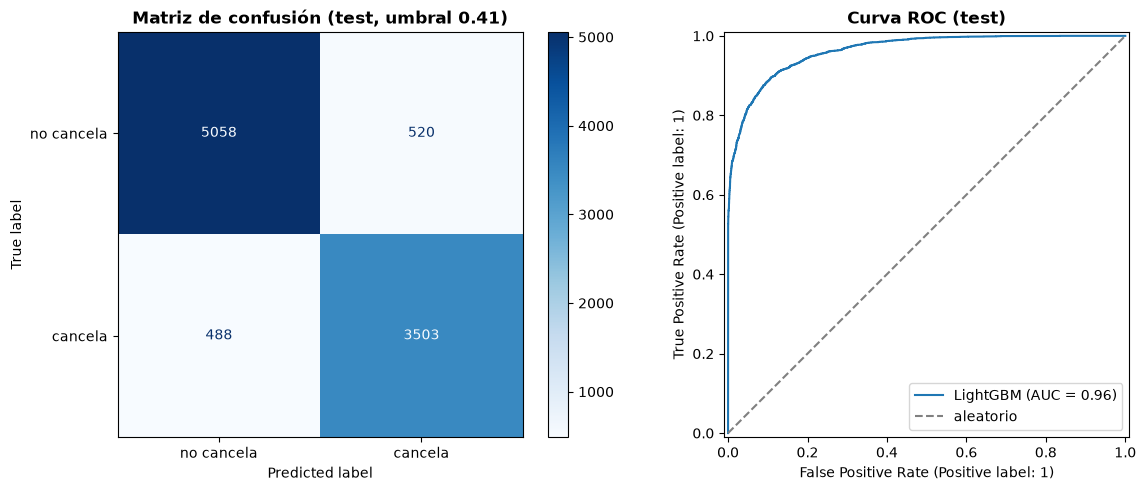

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, display_labels=["no cancela", "cancela"], cmap="Blues", ax=axes[0])
axes[0].set_title(f"Matriz de confusión (test, umbral {decision_threshold:.2f})", fontweight="bold")
RocCurveDisplay.from_predictions(y_test, test_probabilities, name="LightGBM", ax=axes[1])
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="aleatorio")
axes[1].legend()
axes[1].set_title("Curva ROC (test)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "15_confusion_matrix_roc_test.png", dpi=300)
plt.show()

## 7.4 Análisis de errores por segmento

In [6]:
train_duplicate_keys = set(pd.util.hash_pandas_object(train_reservations.drop(columns=TARGET), index=False))
test_duplicate_keys = pd.util.hash_pandas_object(test_reservations.drop(columns=TARGET), index=False)
test_results = test_reservations.assign(
    prediction=test_predictions,
    duplicate_in_train=np.where(test_duplicate_keys.isin(train_duplicate_keys), "sí", "no"),
)


def segment_balanced_accuracy(column):
    return (test_results.groupby(column)
            .apply(lambda segment: pd.Series({
                "reservas": len(segment),
                "tasa de cancelación": segment[TARGET].mean(),
                "balanced_accuracy": balanced_accuracy_score(segment[TARGET], segment["prediction"]) if segment[TARGET].nunique() == 2 else np.nan,
                "accuracy": (segment[TARGET] == segment["prediction"]).mean(),
            }), include_groups=False)
            .round(3))


for column in ["duplicate_in_train", "reservation_commitment", "client_type"]:
    display(segment_balanced_accuracy(column))

,reservas,tasa de cancelación,balanced_accuracy,accuracy
duplicate_in_train,,,,
no,5878.0,0.284,0.799,0.834
sí,3691.0,0.629,0.990,0.991


,reservas,tasa de cancelación,balanced_accuracy,accuracy
reservation_commitment,,,,
locked_allocation,1597.0,0.999,1.000,1.000
no_commitment,7972.0,0.300,0.852,0.874


,reservas,tasa de cancelación,balanced_accuracy,accuracy
client_type,,,,
cloud_marketplace,4630.0,0.373,0.824,0.830
enterprise_client,350.0,0.243,0.861,0.923
high_priority_partner,24.0,0.417,0.707,0.708
independent_client,757.0,0.165,0.731,0.888
managed_account,2109.0,0.430,0.966,0.967
research_consortium,1642.0,0.688,0.981,0.983
sponsored_project,57.0,0.158,0.712,0.895


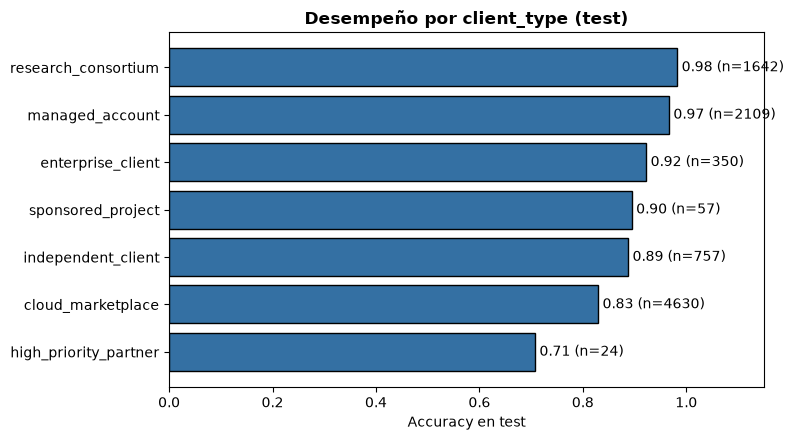

In [7]:
segment_accuracy = segment_balanced_accuracy("client_type").sort_values("accuracy")
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(segment_accuracy.index, segment_accuracy["accuracy"], color="#3470a3", edgecolor="black")
ax.bar_label(bars, labels=[f"{accuracy:.2f} (n={int(size)})" for accuracy, size in segment_accuracy[["accuracy", "reservas"]].values], padding=3)
ax.set_xlim(0, 1.15)
ax.set_xlabel("Accuracy en test")
ax.set_title("Desempeño por client_type (test)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "16_error_analysis_client_type.png", dpi=300)
plt.show()

## 7.5 Importancia de variables

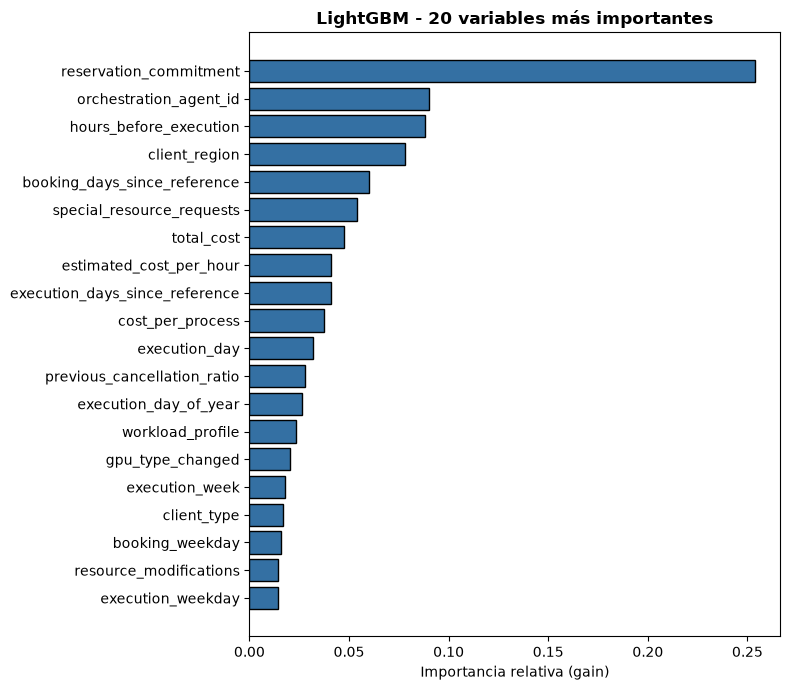

In [8]:
feature_importance = pd.Series(final_model.booster_.feature_importance(importance_type="gain"),
                               index=X_train_category.columns).sort_values().tail(20)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(feature_importance.index, feature_importance.values / feature_importance.sum(), color="#3470a3", edgecolor="black")
ax.set_xlabel("Importancia relativa (gain)")
ax.set_title("LightGBM - 20 variables más importantes", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "17_feature_importance.png", dpi=300)
plt.show()

## 7.6 Modelo para la competencia: reentrenamiento con todas las reservas (train + test)
Mismos hiperparámetros y umbral; más datos para el modelo que se entrega.

In [9]:
all_reservations = pd.concat([train_reservations, test_reservations], ignore_index=True)
X_all = engineer_features(all_reservations)
all_categories = {column: sorted(X_all[column].unique()) for column in CATEGORICAL_FEATURES}
X_all_category = encode_categories(X_all, all_categories)

submission_model = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, **lightgbm_hyperparameters)
submission_model.fit(X_all_category, all_reservations[TARGET])

model_bundle = {
    "booster_model": submission_model.booster_.model_to_string(),
    "categories": all_categories,
    "feature_names": list(X_all_category.columns),
    "threshold": decision_threshold,
}
joblib.dump(model_bundle, MODEL_PATH, compress=3)
print(f"{MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1e6:.1f} MB")

cancellation_model.joblib: 2.4 MB


## 7.7 Verificación del predictor
Lote sin `canceled_job`, `execution_status` ni `execution_status_date`, como en la evaluación.

In [10]:
raw_reservations = pd.read_csv(DATA_PATH / "gpu_resource_reservations.csv")
evaluation_batch = raw_reservations.drop(columns=["canceled_job", "execution_status", "execution_status_date"])

batch_predictions = predictor(evaluation_batch)
shuffled_order = np.random.default_rng(RANDOM_STATE).permutation(len(evaluation_batch))
shuffled_predictions = predictor(evaluation_batch.iloc[shuffled_order])
array_predictions = predictor(evaluation_batch.to_numpy())

print("Una predicción por reserva:", len(batch_predictions) == len(evaluation_batch))
print("Valores:", np.unique(batch_predictions))
print("Conserva el orden de entrada:", np.array_equal(shuffled_predictions, batch_predictions[shuffled_order]))
print("Acepta numpy array:", np.array_equal(array_predictions, batch_predictions))
print(f"Una sola reserva: {predictor(evaluation_batch.iloc[[0]])}")

Una predicción por reserva: True
Valores: [0 1]
Conserva el orden de entrada: True
Acepta numpy array: True
Una sola reserva: [0]


## Conclusiones
- Test: BA 0.892 y ROC-AUC 0.963, consistentes con la validación cruzada (0.889 / 0.962): no hay sobreajuste a la validación.
- Los errores se concentran en reservas sin una reserva idéntica en train (BA 0.799), `no_commitment` y clientes `cloud_marketplace` / `independent_client`.
- `locked_allocation` se predice sin errores.
- Entrega: `predictor.py` + `cancellation_model.joblib`, reentrenado con las 47,842 reservas y umbral 0.41.